# LITE: final results with our improvements

This notebook does **no training**. It loads the saved LITE models in `final_models/`, runs them on each dataset's official test set, applies the improvement chosen for that dataset, and computes every table and graph from those predictions. Paper numbers are read from the repo's `results.csv` and `results_ensemble_study.csv`.

| Dataset | Improvement used |
|---|---|
| PigAirwayPressure | Scale-only augmentation (random amplitude scaling during training, sd 0.1) |
| Wine | Scale-only augmentation |
| ShapeletSim | Scale-only augmentation |
| SemgHandMovementCh2 | Batch-norm recalibration after training |
| OliveOil | Batch-norm recalibration after training |
| Beef | None: plain LITE (no method beat it) |

**Ensembles** average the softmax outputs of all models in a folder (5 per dataset, 4 for SemgHand), the same way LITETime combines LITE models.

**Batch-norm recalibration:** after training, the batch-norm statistics are recomputed from one pass over the full training set. No retraining, no test data.

**Note:** the improvement for each dataset was picked after seeing test results, so the per-dataset table is optimistic. Recalibration is the one method that could be fixed in advance for every dataset; its effect on all six is shown in section 5.

Run from the `LITE-main` folder (Kernel → Restart & Run All). It takes a few minutes on CPU.

## 1. Setup

In [1]:
import itertools, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import load_data
import run_ablation  # registers the augmentation layer that scale-only models contain (it is off at test time)

MODELS = ROOT / "final_models"
FIGS = ROOT / "experiment_results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
DATASETS = ["PigAirwayPressure", "Wine", "SemgHandMovementCh2", "OliveOil", "ShapeletSim", "Beef"]

# Chart style
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, NEUTRAL, PAPER = "#2a78d6", "#eb6834", "#e34948", "#f0efec", "#a3a29c"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
})

CHOICES = {  # dataset: (model folder, recalibrate?, label)
    "PigAirwayPressure": ("scale_0.1", False, "Scale-only augmentation"),
    "Wine": ("scale_0.1", False, "Scale-only augmentation"),
    "ShapeletSim": ("scale_0.1", False, "Scale-only augmentation"),
    "SemgHandMovementCh2": ("plain", True, "Batch-norm recalibration"),
    "OliveOil": ("plain", True, "Batch-norm recalibration"),
    "Beef": ("plain", False, "Plain LITE"),
}

## 2. Paper numbers (from the repo's CSV files)

In [2]:
paper = pd.read_csv(ROOT / "results.csv").set_index("dataset")[["LITE", "LITETime"]] * 100
paper_k = pd.read_csv(ROOT / "results_ensemble_study.csv").set_index("dataset") * 100
display(paper.loc[DATASETS].round(1))

,LITE,LITETime
dataset,,
PigAirwayPressure,34.7,47.1
Wine,64.1,66.7
SemgHandMovementCh2,47.9,51.1
OliveOil,69.3,80.0
ShapeletSim,73.8,75.0
Beef,72.0,76.7


## 3. Run every saved model on the test set

For each model: test predictions as saved, then test predictions after batch-norm recalibration.

In [3]:
def recalibrate(model, x_train):
    layers = list(model._flatten_layers())
    augs = [l for l in layers if isinstance(l, run_ablation.TimeSeriesAugment)]
    saved = [(l.scale, l.jitter, l.max_shift) for l in augs]
    for l in augs:  # use the real training data, not augmented copies
        l.scale = l.jitter = l.max_shift = 0.0
    bns = [l for l in layers if isinstance(l, tf.keras.layers.BatchNormalization)]
    momenta = [l.momentum for l in bns]
    for l in bns:
        l.momentum = 0.0  # one training-mode pass replaces the moving statistics with full-training-set statistics
    model(x_train, training=True)
    for l, m in zip(bns, momenta):
        l.momentum = m
    for l, s in zip(augs, saved):
        l.scale, l.jitter, l.max_shift = s


DATA = {d: load_data(file_name=d) for d in DATASETS}
PROBS = {}  # (dataset, folder) -> {seed: (probs_as_saved, probs_recalibrated)}
for d in DATASETS:
    x_train, _, x_test, _ = DATA[d]
    for folder in sorted(p.name for p in (MODELS / d).iterdir() if p.is_dir()):
        xtr, xte = x_train, x_test
        if "difference" in folder:
            xtr, xte = run_ablation.add_first_difference(xtr), run_ablation.add_first_difference(xte)
        seeds = {}
        for path in sorted((MODELS / d / folder).glob("seed_*.keras"), key=lambda p: int(p.stem[5:])):
            model = tf.keras.models.load_model(path, compile=False)
            before = model.predict(xte, verbose=0)
            recalibrate(model, xtr)
            seeds[int(path.stem[5:])] = (before, model.predict(xte, verbose=0))
            tf.keras.backend.clear_session()
        PROBS[(d, folder)] = seeds
        print(f"{d:20s} {folder:18s} seeds {sorted(seeds)}")

PigAirwayPressure    plain              seeds [5, 6, 7, 8, 9]


PigAirwayPressure    plain_10_seeds     seeds [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


PigAirwayPressure    scale_0.1          seeds [5, 6, 7, 8, 9]


Wine                 plain              seeds [0, 1, 2, 3, 4]


Wine                 scale_0.1          seeds [0, 1, 2, 3, 4]


SemgHandMovementCh2  first_difference   seeds [0, 1, 2]


... (8 outputs left out)

Beef                 first_difference   seeds [0, 1, 2, 3, 4]


Beef                 plain              seeds [0, 1, 2, 3, 4]


Beef                 scale_0.05         seeds [0, 1, 2, 3, 4]


Beef                 scale_0.1          seeds [0, 1, 2, 3, 4]


In [4]:
def acc(y, probs):
    return 100 * accuracy_score(y, np.mean(probs, 0).argmax(1))

rows = []
for (d, folder), seeds in PROBS.items():
    y = DATA[d][3]
    for recal in (False, True):
        ps = [seeds[s][recal] for s in sorted(seeds)]
        rows.append({"dataset": d, "models": folder, "recalibrated": recal, "n_models": len(ps),
                     "single_mean": np.mean([acc(y, [p]) for p in ps]),
                     "single_min": np.min([acc(y, [p]) for p in ps]),
                     "single_max": np.max([acc(y, [p]) for p in ps]),
                     "ensemble": acc(y, ps),
                     "ensemble_macro_f1": 100 * f1_score(y, np.mean(ps, 0).argmax(1), average="macro")})
allres = pd.DataFrame(rows)
allres.round(2).to_csv(ROOT / "experiment_results" / "final_all_models_computed.csv", index=False)
display(allres.round(1))

,dataset,models,recalibrated,n_models,single_mean,single_min,single_max,ensemble,ensemble_macro_f1
0,PigAirwayPressure,plain,False,5,40.8,38.5,46.6,53.4,53.0
1,PigAirwayPressure,plain,True,5,46.5,41.3,50.5,54.8,54.6
2,PigAirwayPressure,plain_10_seeds,False,10,32.9,6.7,46.6,49.0,48.9
3,PigAirwayPressure,plain_10_seeds,True,10,40.2,20.2,49.5,51.0,50.4
4,PigAirwayPressure,scale_0.1,False,5,42.9,31.2,56.2,60.6,57.3
5,PigAirwayPressure,scale_0.1,True,5,51.8,43.8,59.1,60.1,58.6
6,Wine,plain,False,5,63.0,55.6,74.1,55.6,44.6
7,Wine,plain,True,5,78.5,70.4,85.2,83.3,83.3
8,Wine,scale_0.1,False,5,70.4,50.0,94.4,87.0,86.8
9,Wine,scale_0.1,True,5,80.4,75.9,83.3,79.6,79.5


## 4. Final results: our improvement per dataset vs the paper

`plain` = our reproduction of plain LITE with the same seeds. Accuracies in %.

In [5]:
def get(d, folder, recal):
    return allres[(allres.dataset == d) & (allres.models == folder) & (allres.recalibrated == recal)].iloc[0]

final = []
for d, (folder, recal, label) in CHOICES.items():
    base, ours = get(d, "plain", False), get(d, folder, recal)
    final.append({"dataset": d, "improvement": label, "models": int(ours.n_models),
                  "paper LITE": paper.loc[d, "LITE"], "paper LITETime": paper.loc[d, "LITETime"],
                  "plain single (mean)": base.single_mean, "plain ensemble": base.ensemble,
                  "ours single (mean)": ours.single_mean, "ours ensemble": ours.ensemble,
                  "ours ensemble macro-F1": ours.ensemble_macro_f1,
                  "gain vs LITETime (pts)": ours.ensemble - paper.loc[d, "LITETime"],
                  "test series": len(DATA[d][3])})
final = pd.DataFrame(final).set_index("dataset")
final.round(2).to_csv(ROOT / "experiment_results" / "final_results_computed.csv")
display(final.round(1))

,improvement,models,paper LITE,paper LITETime,plain single (mean),plain ensemble,ours single (mean),ours ensemble,ours ensemble macro-F1,gain vs LITETime (pts),test series
dataset,,,,,,,,,,,
PigAirwayPressure,Scale-only augmentation,5,34.7,47.1,40.8,53.4,42.9,60.6,57.3,13.5,208
Wine,Scale-only augmentation,5,64.1,66.7,63.0,55.6,70.4,87.0,86.8,20.4,54
ShapeletSim,Scale-only augmentation,5,73.8,75.0,72.7,73.9,73.7,76.1,75.7,1.1,180
SemgHandMovementCh2,Batch-norm recalibration,4,47.9,51.1,46.8,52.0,49.5,54.2,54.2,3.1,450
OliveOil,Batch-norm recalibration,5,69.3,80.0,79.3,83.3,82.7,83.3,73.8,3.3,30
Beef,Plain LITE,5,72.0,76.7,72.0,76.7,72.0,76.7,75.7,-0.0,30


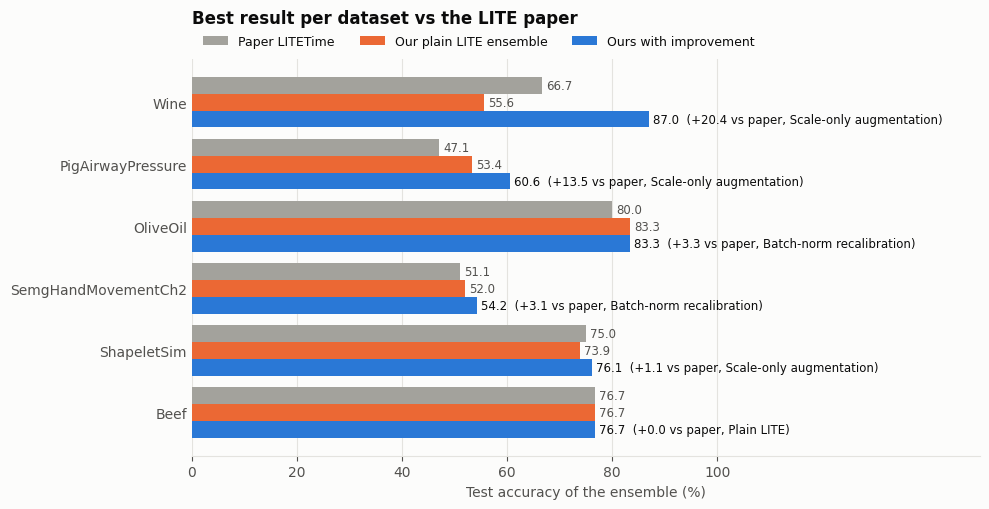

In [6]:
order = final.sort_values("gain vs LITETime (pts)", ascending=True).index
y = np.arange(len(order))
h = 0.27
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(y + h, final.loc[order, "paper LITETime"], h, color=PAPER, label="Paper LITETime")
ax.barh(y, final.loc[order, "plain ensemble"], h, color=ORANGE, label="Our plain LITE ensemble")
ax.barh(y - h, final.loc[order, "ours ensemble"], h, color=BLUE, label="Ours with improvement")
for yi, d in zip(y, order):
    r = final.loc[d]
    gain = round(r["gain vs LITETime (pts)"], 1) + 0.0  # + 0.0 turns -0.0 into 0.0
    ax.text(r["ours ensemble"] + 0.8, yi - h, f"{r['ours ensemble']:.1f}  ({gain:+.1f} vs paper, {r['improvement']})",
            va="center", fontsize=8.5, color=INK)
    ax.text(r["paper LITETime"] + 0.8, yi + h, f"{r['paper LITETime']:.1f}", va="center", fontsize=8.5, color=INK2)
    ax.text(r["plain ensemble"] + 0.8, yi, f"{r['plain ensemble']:.1f}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, order)
ax.set_xlim(0, 150)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Test accuracy of the ensemble (%)")
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Best result per dataset vs the LITE paper", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "best_vs_paper.png", dpi=150)
plt.show()

## 5. What each method did (saved models, same seeds and machine)

Change in mean single-model accuracy against plain LITE on the **same seeds**, in percentage points. Blank = no saved models for that method on that dataset.

,Scale 0.1,Scale 0.05,First difference,Validation,Recalibration
PigAirwayPressure,2.1,NaN,NaN,NaN,5.8
Wine,7.4,NaN,NaN,NaN,15.6
SemgHandMovementCh2,NaN,NaN,-2.2,-0.9,2.7
OliveOil,-4.7,-6.7,NaN,NaN,3.3
ShapeletSim,1.0,-0.6,NaN,NaN,-0.4
Beef,-1.3,-0.7,2.7,NaN,-1.3


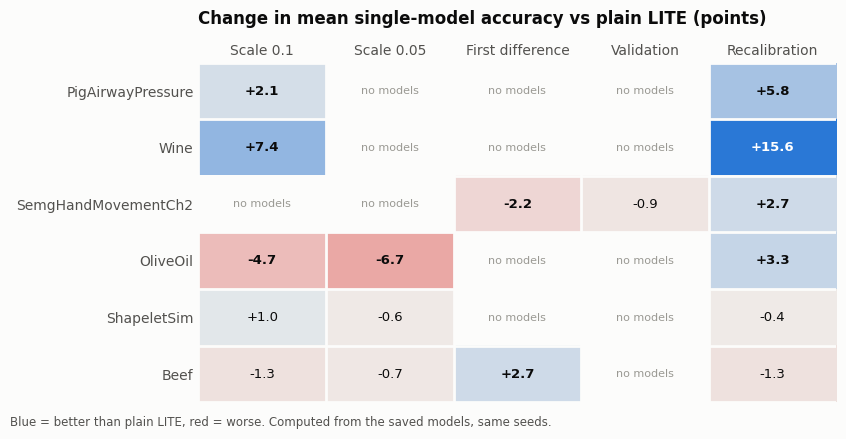

In [7]:
METHODS = [("Scale 0.1", "scale_0.1", False), ("Scale 0.05", "scale_0.05", False),
           ("First difference", "first_difference", False), ("Validation", "validation", False),
           ("Recalibration", "plain", True)]

def seed_mean(d, folder, recal, seeds):
    y = DATA[d][3]
    return np.mean([acc(y, [PROBS[(d, folder)][s][recal]]) for s in seeds])

effects = pd.DataFrame(index=DATASETS, columns=[m[0] for m in METHODS], dtype=float)
for d in DATASETS:
    for name, folder, recal in METHODS:
        if (d, folder) in PROBS:
            common = sorted(set(PROBS[(d, folder)]) & set(PROBS[(d, "plain")]))
            effects.loc[d, name] = seed_mean(d, folder, recal, common) - seed_mean(d, "plain", False, common)
display(effects.round(1))

lim = np.nanmax(np.abs(effects.values))
cmap = LinearSegmentedColormap.from_list("div", [RED, NEUTRAL, BLUE])
cmap.set_bad(SURFACE)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.imshow(np.ma.masked_invalid(effects.values.astype(float)), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
for i in range(effects.shape[0]):
    for j in range(effects.shape[1]):
        v = effects.iat[i, j]
        if np.isnan(v):
            ax.text(j, i, "no models", ha="center", va="center", fontsize=8, color="#9a9993")
        else:
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9.5,
                    color="white" if abs(v) > 0.55 * lim else INK, fontweight="bold" if abs(v) >= 2 else "normal")
ax.set_xticks(range(effects.shape[1]), effects.columns)
ax.set_yticks(range(effects.shape[0]), effects.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, effects.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, effects.shape[0]), minor=True)
ax.grid(which="minor", color=SURFACE, lw=2)
ax.tick_params(which="minor", length=0)
ax.set_title("Change in mean single-model accuracy vs plain LITE (points)", pad=28)
fig.text(0.01, 0.02, "Blue = better than plain LITE, red = worse. Computed from the saved models, same seeds.",
         fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGS / "method_effects.png", dpi=150)
plt.show()

### Earlier experiments without saved models (from the run logs)

The full augmentation, its single components and validation-based training were run before checkpoints were kept, so these come from the per-run CSV logs in `experiment_results/`. Mean single-model test accuracy in %.

In [8]:
E = ROOT / "experiment_results"
pig_orig = pd.read_csv(E / "pigairway_1500ep_kaggle_seeds_0_4" / "results_per_run.csv")
full = pd.read_csv(E / "augment_1500ep_kaggle" / "all_results.csv")
parts = pd.read_csv(E / "augment_components_kaggle" / "all_results.csv")
full["variant"] = full.condition.map({"augment": "full augmentation", "original": "plain"})
pig_orig = pig_orig[pig_orig.condition == "original"].assign(variant="plain")
logs = pd.concat([pig_orig, full, parts], ignore_index=True)
logs = logs[(logs.dataset == "PigAirwayPressure") | (logs.seed <= 2)]  # SemgHand components were run on seeds 0-2
aug_table = (logs.groupby(["variant", "dataset"]).accuracy.mean().unstack() * 100).round(1)
display(aug_table.loc[["plain", "full augmentation", "shift_only", "scale_only", "jitter_only"]])

semg = pd.read_csv(E / "semghand_1500ep_seeds_0_4" / "results_per_run.csv")
display((semg.groupby("condition").accuracy.agg(["mean", "count"]).assign(mean=lambda t: t["mean"] * 100)).round(1)
        .rename(columns={"mean": "SemgHand mean accuracy (%)", "count": "seeds"}))

dataset,PigAirwayPressure,SemgHandMovementCh2
variant,,
plain,26.3,45.1
full augmentation,9.6,41.0
shift_only,27.3,45.1
scale_only,33.8,42.3
jitter_only,13.7,46.1


,SemgHand mean accuracy (%),seeds
condition,,
first_difference,42.5,5
original,46.6,5
validation,46.4,5
validation_and_difference,42.8,5
validation_refit,38.3,5


## 6. Recalibration on PigAirwayPressure ensembles

Ten plain LITE models (seeds 0–9). For each ensemble size k, accuracy is averaged over every possible set of k models.

,k,plain,plain + recalibration,paper LITETime-k
0,1,32.9,40.2,40.5
1,2,38.7,45.9,44.5
2,3,42.7,48.6,46.7
3,4,45.1,50.0,47.7
4,5,46.6,50.7,48.3
5,6,47.4,50.9,48.8
6,7,48.1,51.0,49.1
7,8,48.6,50.9,49.4
8,9,48.9,50.8,49.9
9,10,49.0,51.0,49.5


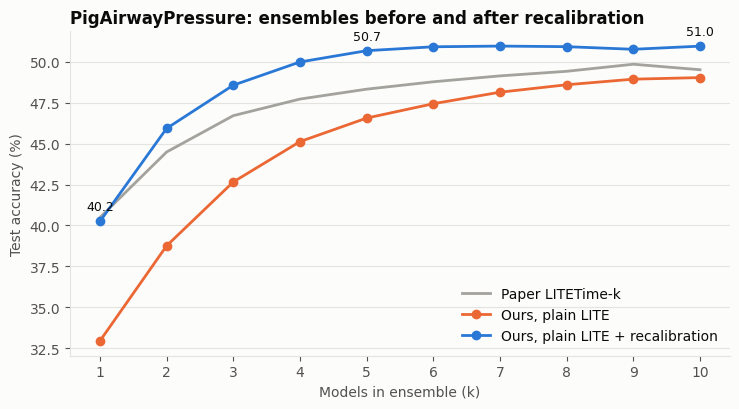

In [9]:
y = DATA["PigAirwayPressure"][3]
seeds = PROBS[("PigAirwayPressure", "plain_10_seeds")]
ks = list(range(1, len(seeds) + 1))
curve = {False: [], True: []}
for recal in (False, True):
    ps = [seeds[s][recal] for s in sorted(seeds)]
    for k in ks:
        curve[recal].append(np.mean([acc(y, [ps[i] for i in c]) for c in itertools.combinations(range(len(ps)), k)]))
pig_curve = pd.DataFrame({"k": ks, "plain": curve[False], "plain + recalibration": curve[True],
                          "paper LITETime-k": paper_k.loc["PigAirwayPressure"].values[: len(ks)]})
display(pig_curve.round(1))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(ks, pig_curve["paper LITETime-k"], color=PAPER, lw=2, label="Paper LITETime-k")
ax.plot(ks, pig_curve["plain"], color=ORANGE, lw=2, marker="o", ms=6, label="Ours, plain LITE")
ax.plot(ks, pig_curve["plain + recalibration"], color=BLUE, lw=2, marker="o", ms=6, label="Ours, plain LITE + recalibration")
for k in (1, 5, 10):
    v = pig_curve.loc[pig_curve.k == k, "plain + recalibration"].item()
    ax.annotate(f"{v:.1f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xticks(ks)
ax.set_xlabel("Models in ensemble (k)")
ax.set_ylabel("Test accuracy (%)")
ax.yaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("PigAirwayPressure: ensembles before and after recalibration")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "recalibration_pig.png", dpi=150)
plt.show()

## 7. Every seed: plain LITE vs our improvement

Each line is one seed. Single models only (no ensembling).

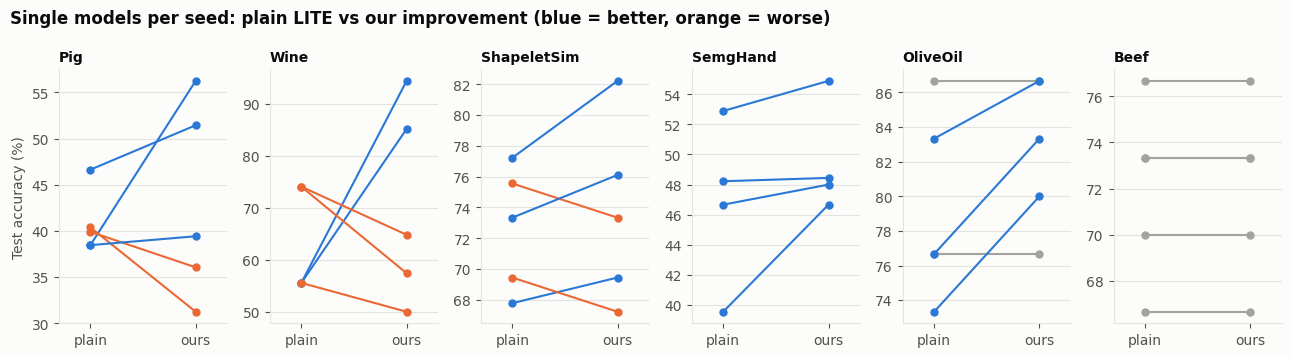

In [10]:
fig, axes = plt.subplots(1, len(CHOICES), figsize=(13, 3.6), sharey=False)
for ax, (d, (folder, recal, label)) in zip(axes, CHOICES.items()):
    y = DATA[d][3]
    common = sorted(set(PROBS[(d, folder)]) & set(PROBS[(d, "plain")]))
    a = [acc(y, [PROBS[(d, "plain")][s][False]]) for s in common]
    b = [acc(y, [PROBS[(d, folder)][s][recal]]) for s in common]
    for va, vb in zip(a, b):
        ax.plot([0, 1], [va, vb], color=BLUE if vb > va else (ORANGE if vb < va else PAPER), lw=1.5, marker="o", ms=5)
    ax.set_xticks([0, 1], ["plain", "ours"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(d.replace("MovementCh2", "").replace("AirwayPressure", ""), fontsize=10)
    ax.yaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Test accuracy (%)")
fig.suptitle("Single models per seed: plain LITE vs our improvement (blue = better, orange = worse)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "per_seed.png", dpi=150)
plt.show()

## 8. Confusion matrices of our final ensembles (rows = true class, normalised)

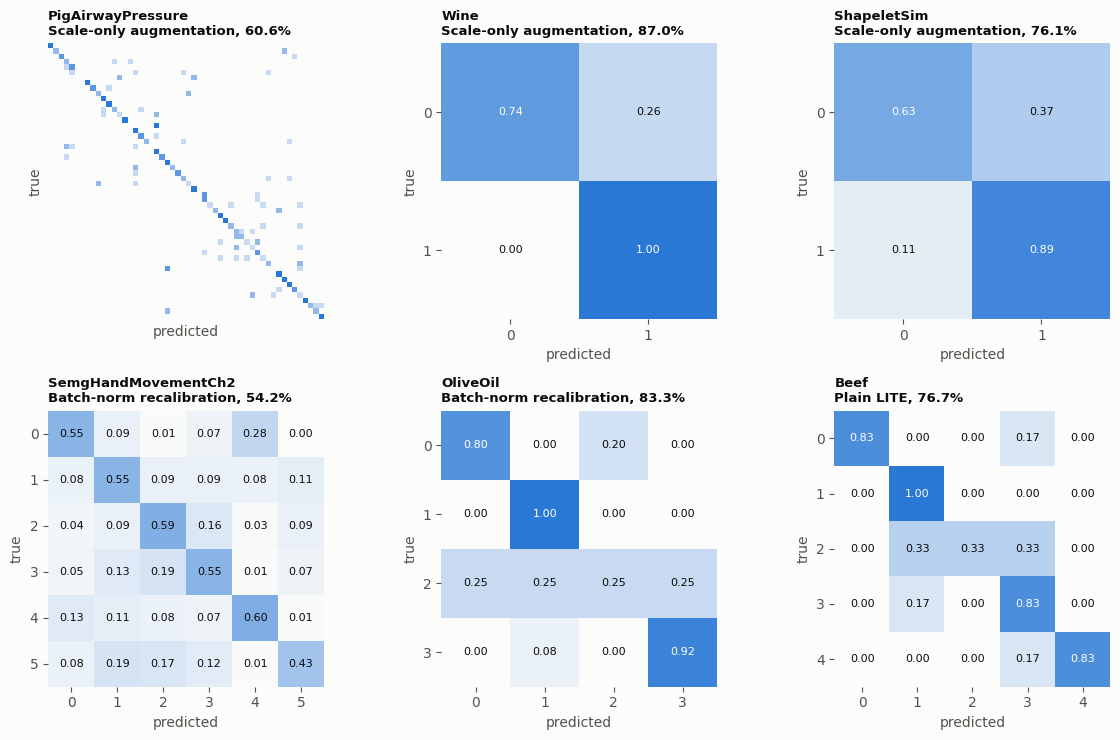

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, (d, (folder, recal, label)) in zip(axes.flat, CHOICES.items()):
    y = DATA[d][3]
    pred = np.mean([p[recal] for p in PROBS[(d, folder)].values()], 0).argmax(1)
    cm = confusion_matrix(y, pred, normalize="true")
    ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("seq", [SURFACE, BLUE]), vmin=0, vmax=1)
    n = cm.shape[0]
    if n <= 6:
        for i in range(n):
            for j in range(n):
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > 0.6 else INK)
        ax.set_xticks(range(n)); ax.set_yticks(range(n))
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{d}\n{label}, {accuracy_score(y, pred) * 100:.1f}%", fontsize=9.5)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "confusion_matrices.png", dpi=150)
plt.show()